In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/photo_colorization'
for f in ['data', 'models', 'results', 'test_photos']:
    os.makedirs(f'{BASE}/{f}', exist_ok=True)
print("Ready:", os.listdir(BASE))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: ['data', 'models', 'results', 'test_photos']


In [4]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))


True Tesla T4


In [6]:
!git clone https://github.com/richzhang/colorization.git
%cd colorization

Cloning into 'colorization'...
remote: Enumerating objects: 4873, done.
remote: Counting objects: 100% (166/166), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 4873 (delta 133), reused 121 (delta 121), pack-reused 4707 (from 1)
Receiving objects: 100% (4873/4873), 177.90 MiB | 14.74 MiB/s, done.
Resolving deltas: 100% (422/422), done.
/content/colorization/colorization


In [12]:
import torch
import matplotlib.pyplot as plt
from colorizers import *

colorizer = eccv16(pretrained=True).eval().cuda()

def colorize(photo_name, show=True):
    path = f'{BASE}/test_photos/{photo_name}'
    img = load_img(path)
    tens_l_orig, tens_l_rs = preprocess_img(img, HW=(256, 256))
    out = colorizer(tens_l_rs.cuda()).cpu()
    color = postprocess_tens(tens_l_orig, out)
    gray  = postprocess_tens(tens_l_orig, torch.cat((0*tens_l_orig, 0*tens_l_orig), dim=1))

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(gray);  ax[0].set_title("Grayscale"); ax[0].axis('off')
    ax[1].imshow(color); ax[1].set_title("Pretrained (Zhang et al.)"); ax[1].axis('off')
    name_only = photo_name.rsplit('.', 1)[0]
    plt.savefig(f'{BASE}/results/{name_only}_result.png', bbox_inches='tight')
    if show: plt.show()
    plt.close()

Saving WhatsApp Image 2023-10-15 at 21.51.19_ecf92a74.jpg to WhatsApp Image 2023-10-15 at 21.51.19_ecf92a74 (1).jpg


/content/colorization/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 54 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))


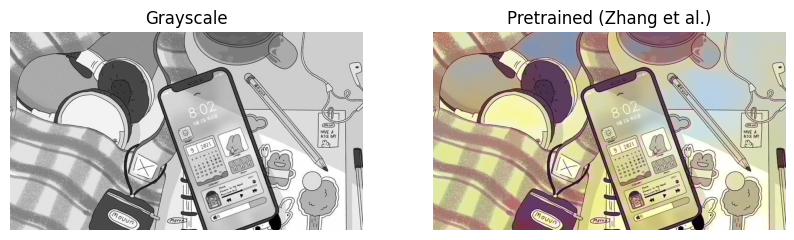

In [13]:
import os, shutil
from google.colab import files

uploaded = files.upload()

for name in uploaded.keys():
    # spaces hata ke simple naam banao (WhatsApp wale lambe naam ke liye)
    clean = name.replace(' ', '_')
    os.makedirs(f'{BASE}/test_photos', exist_ok=True)
    shutil.move(name, f'{BASE}/test_photos/{clean}')
    colorize(clean)
